# 01 · Players and the data-generating process

**Question.** Who signs up for Questline, how likely is each new player to finish a first milestone, and how does the Starter Bonus change that? This notebook defines the simulated world that the live page streams from, with the true answer known in advance.

**Milestone.** M1 · **Theory notes:** [ate-estimators](../docs/theory/ate-estimators.md), [hte](../docs/theory/hte.md)

## The case study

**Questline** is a fictional rewarded-gaming marketplace. Players discover mobile games on Questline and earn coins for reaching milestones in them. Game studios pay Questline for every milestone a player reaches, and Questline passes part of that on to the player as the reward.

Many new players sign up and never finish a first game. The product team wants to test a **Starter Bonus**: the coins for the first, easy milestone (reach level 5) are paid straight away, instead of being held until level 10.

## The experiment

For two weeks, every new player is assigned once, at sign-up, to one of two arms: the standard reward schedule (**control**) or the Starter Bonus (**treatment**).

| Element | Choice |
|---|---|
| Unit | New player, assigned once at sign-up |
| Split | 50 / 50, by a hash of player ID and experiment key |
| Primary metric | **Activation**: completes a first paid milestone within 72 hours (yes / no) |
| Guardrail (later) | Net revenue per player (studio payments minus rewards paid) |
| Covariates logged at sign-up | Country tier, device, acquisition channel, sign-up hour and weekday |
| Decision rule | Ship if the always-valid 95% interval for the lift is entirely above zero; don't ship if entirely below; otherwise keep collecting up to a maximum sample |

Activation takes 72 hours to observe, so a player only enters the analysis when their 72-hour window closes.

In this notebook we build the **simulator**: a model of the players with a known true effect. Because we set the truth ourselves, later notebooks can check whether the statistics recover it.

## 1. Model

**Arrivals.** Each hour $h$ of the experiment brings a Poisson number of sign-ups, with a daily and weekly rhythm:

$$
N_h \sim \text{Poisson}(\lambda_h), \qquad \lambda_h = \bar\lambda \cdot s_{\text{hour}}(h \bmod 24) \cdot s_{\text{day}}(\lfloor h/24 \rfloor \bmod 7)
$$

where $\bar\lambda$ is the average sign-ups per hour and both shape curves average to 1.

**Covariates.** For each player $i$: country tier $T_i \in \{1,2,3\}$, device $D_i \in \{\text{iPhone}, \text{Android}\}$ (iPhones are more common in tier 1), channel $C_i \in \{\text{Organic}, \text{Paid social}, \text{Referral}\}$, and whether they signed up in the evening, $E_i$.

**Engagement, and what we can see of it before sign-up.** Players differ in how keen they are to play, a latent engagement level $U_i \sim \mathcal{N}(0, 1)$ that nobody observes directly. Three signals known *before* sign-up carry part of it, as they would in a real user-acquisition pipeline:

| Signal | Model | Available for |
|---|---|---|
| Games installed in the 30 days before sign-up, $G_i$ | $G_i \sim \text{Poisson}\big(e^{\gamma_0 + \gamma_G U_i}\big)$ | everyone (from the attribution partner) |
| Seconds from ad click to install, $K_i$ | $\log K_i = \kappa_0 - \kappa_K U_i + \varepsilon_i$ | everyone |
| Partner engagement score $S_i \in (0,1)$ | $S_i = \sigma(\lambda_S U_i + \nu_i)$ | paid-social installs only |

None of them is affected by the experiment, so they are fair game for variance reduction (CUPAC, notebook 06).

**Baseline activation** (control) follows a logistic model:

$$
p_0(x_i) = \sigma\!\left(\beta_0 + \beta_{T_i} + \beta_{D_i} + \beta_{C_i} + \beta_E E_i + \beta_U U_i\right), \qquad \sigma(z) = \frac{1}{1+e^{-z}}
$$

The intercept $\beta_0$ is calibrated so the average baseline is the target rate (22%).

**Treatment effect.** The Starter Bonus adds a lift on the probability scale that varies by segment:

$$
p_1(x_i) = p_0(x_i) + \tau(x_i), \qquad \tau(x_i) = \bar\tau \cdot \frac{m_{T_i}\, m_{C_i}}{\mathbb{E}[m_T m_C]}
$$

so the population-average lift is exactly the preset $\bar\tau$ (0, +2 or +5 points). The multipliers $m$ encode a designed-in story: the bonus matters more where 40 coins are worth more (tier 3) and for paid-social players who arrive with weaker intent. The targeting article (notebook 08) will try to recover this.

**Assignment** uses a hash, never the covariates:

$$
u_i = \frac{\text{MurmurHash3}_{32}(\text{player\_id}_i : \text{experiment\_key})}{2^{32}} \in [0, 1), \qquad W_i = \mathbb{1}[u_i < 0.5]
$$

**Outcome.** $Y_i \sim \text{Bernoulli}\big(p_{W_i}(x_i)\big)$. The estimand is the average treatment effect $\tau = \mathbb{E}[p_1(X) - p_0(X)] = \bar\tau$.

**Journey** (for the player story only, not the analysis): time to start a game and time to reach the milestone are log-normal, and completions are truncated to the 72-hour window.

## 2. Libraries

| Library | Used for |
|---|---|
| `numpy` | Seeded random draws (`SeedSequence`, one named stream per part of the model) and the simulation itself |
| `scipy` | Logistic function, `brentq` to calibrate the intercept, χ² test for the split |
| `mmh3` | MurmurHash3, the hash behind assignment. The browser port is tested against fixtures from this package |
| `statsmodels` | Logit fit that recovers the model coefficients from simulated data |
| `causalml` | `create_table_one`: the balance table with standardised mean differences (SMD) |
| `scikit-learn` | `HistGradientBoostingClassifier`: how well activation can be predicted before sign-up |
| `pandas` | Tables and descriptives |
| `matplotlib`, `seaborn` | Figures, styled by `ablab.viz` to match the page |
| `ipywidgets` | The slider cell at the end |

The data-generating process itself is plain numpy. Generic generators (for example in `doubleml` or `econml`) produce anonymous continuous covariates; ours needs sign-up hours, segments and a hash split, so it is written for this case and then checked with a logit fit (section 4).

In [1]:
import mmh3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from matplotlib.ticker import PercentFormatter
from scipy.optimize import brentq
from scipy.special import expit
from scipy.stats import chisquare
from causalml.match import create_table_one

from ablab.viz import use_style, savefig, CONTROL, TREAT, INK, MUTED, GOLD_CMAP

use_style()
pd.set_option("display.precision", 3)

SEED = 20261012
print(f"seed = {SEED}")

seed = 20261012


### The configuration

Every parameter of the simulated world lives in this one block. After review it moves to a documented config file that both Python and the browser read.

In [2]:
CONFIG = {
    "experiment_key": "starter-bonus-v1",
    "baseline_rate": 0.22,  # target average activation in control
    "days": 14,
    "arrivals": {
        "per_hour": 300,  # average sign-ups per hour (placeholder; tuned in notebook 04)
        # relative sign-up intensity by weekday, Mon..Sun
        "weekday_shape": [0.90, 0.88, 0.92, 0.97, 1.08, 1.17, 1.10],
    },
    "covariates": {
        "tier": {"levels": ["Tier 1", "Tier 2", "Tier 3"], "p": [0.30, 0.45, 0.25]},
        "device": {"levels": ["iPhone", "Android"], "p_iphone_by_tier": [0.60, 0.35, 0.20]},
        "channel": {"levels": ["Organic", "Paid social", "Referral"], "p": [0.45, 0.40, 0.15]},
        "evening_hours": [18, 24],  # [start, end) local hour counted as evening
    },
    "baseline_logit": {  # effects on the log-odds of activating, control arm
        "tier": [0.25, 0.0, -0.35],
        "device": [0.10, 0.0],
        "channel": [0.20, -0.30, 0.45],
        "evening": 0.15,
        "engagement": 1.2,  # beta_U: effect of latent engagement U ~ N(0, 1)
    },
    "signals": {  # known before sign-up; noisy views of engagement U
        "games_30d": {"log_mean": 0.9, "loading": 0.6},
        "click_to_install_s": {"log_median": 4.094, "loading": 0.45, "noise_sd": 0.8},  # median 60 s
        "partner_score": {"loading": 1.1, "noise_sd": 0.8, "channel": "Paid social"},
    },
    "lift_multiplier": {  # how the Starter Bonus effect varies; normalised to average 1
        "tier": [0.6, 1.0, 1.5],
        "channel": [0.8, 1.25, 0.8],
    },
    "presets": {"No effect": 0.0, "Small real effect": 0.02, "Large effect": 0.05},
    "journey": {
        "p_start_if_not_activated": 0.55,
        "start_median_min": 18, "start_sigma": 1.0,
        "milestone_median_h": 5.0, "milestone_sigma": 1.1,
        "treatment_speedup": 0.85,  # Starter Bonus players reach level 5 a bit faster
        "p_late_finisher": 0.15,  # started, finished after the 72-hour window
    },
}

TIERS = CONFIG["covariates"]["tier"]["levels"]
DEVICES = CONFIG["covariates"]["device"]["levels"]
CHANNELS = CONFIG["covariates"]["channel"]["levels"]
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]


def hour_shape():
    """Relative sign-ups by hour of day: a lunchtime bump and an evening peak, averaging 1."""
    h = np.arange(24)
    night = 0.55 + 0.45 * np.cos(2 * np.pi * (h - 16) / 24)  # quiet around 04:00
    s = 0.25 * night + 0.45 * np.exp(-((h - 12.5) / 2.2) ** 2) + 1.0 * np.exp(-((h - 20.5) / 2.6) ** 2)
    return s / s.mean()


HOUR_SHAPE = hour_shape()
DAY_SHAPE = np.array(CONFIG["arrivals"]["weekday_shape"]) / np.mean(CONFIG["arrivals"]["weekday_shape"])

### Hash assignment

Each player's ID and the experiment key are hashed with MurmurHash3 (32 bits) and scaled to $[0, 1)$. MurmurHash3 is fast, well mixed, and has small, well-tested implementations in both Python (`mmh3`) and JavaScript, so the page and this notebook assign every player to the same arm.

In [3]:
def assignment_u(player_ids, key=CONFIG["experiment_key"]):
    """u in [0, 1) per player; u < 0.5 means Starter Bonus."""
    return np.array([mmh3.hash(f"{pid}:{key}", 0, signed=False) / 2**32 for pid in player_ids])


print(assignment_u(["Q0000000", "Q0000001", "Q0000002"]))

[0.96721754 0.10034181 0.47203685]


### The simulator

One function per part of the model, each with its own random stream, so changing the arrivals never changes who activates.

In [4]:
def streams(seed):
    names = ["arrivals", "covariates", "outcomes", "journey"]
    return dict(zip(names, (np.random.default_rng(s) for s in np.random.SeedSequence(seed).spawn(4))))


def draw_arrivals(rng, cfg=CONFIG):
    hours = np.arange(cfg["days"] * 24)
    lam = cfg["arrivals"]["per_hour"] * HOUR_SHAPE[hours % 24] * DAY_SHAPE[(hours // 24) % 7]
    counts = rng.poisson(lam)
    return hours, lam, counts


def draw_covariates(signup_hour, rng, cfg=CONFIG):
    c, n = cfg["covariates"], len(signup_hour)
    tier = rng.choice(3, size=n, p=c["tier"]["p"])
    device = np.where(rng.random(n) < np.array(c["device"]["p_iphone_by_tier"])[tier], 0, 1)
    channel = rng.choice(3, size=n, p=c["channel"]["p"])
    hod = signup_hour % 24
    evening = (hod >= c["evening_hours"][0]) & (hod < c["evening_hours"][1])
    u = rng.normal(size=n)  # latent engagement, never observed
    sg = cfg["signals"]
    games = rng.poisson(np.exp(sg["games_30d"]["log_mean"] + sg["games_30d"]["loading"] * u))
    k = sg["click_to_install_s"]
    click = np.exp(k["log_median"] - k["loading"] * u + rng.normal(0, k["noise_sd"], n))
    ps = sg["partner_score"]
    has_score = channel == CONFIG["covariates"]["channel"]["levels"].index(ps["channel"])
    score = np.where(has_score, expit(ps["loading"] * u + rng.normal(0, ps["noise_sd"], n)), np.nan)
    return pd.DataFrame({
        "signup_hour": signup_hour, "hour_of_day": hod, "weekday": (signup_hour // 24) % 7,
        "tier": tier, "device": device, "channel": channel, "evening": evening,
        "engagement": u, "games_30d": games, "click_to_install_s": click, "partner_score": score,
    })


def linear_predictor(cov, cfg=CONFIG):
    b = cfg["baseline_logit"]
    return (np.array(b["tier"])[cov.tier] + np.array(b["device"])[cov.device]
            + np.array(b["channel"])[cov.channel] + b["evening"] * cov.evening + b["engagement"] * cov.engagement)


def raw_multiplier(cov, cfg=CONFIG):
    m = cfg["lift_multiplier"]
    return np.array(m["tier"])[cov.tier] * np.array(m["channel"])[cov.channel]

### Calibration on a reference population

We fix two constants once, on a large reference population: the intercept $\beta_0$ that makes the average baseline 22%, and the normaliser $\mathbb{E}[m_T m_C]$ that makes the average lift equal the preset. Both are then written into the config, so every run uses the same world.

In [5]:
def calibrate(cfg=CONFIG, n_ref=400_000, seed=1):
    rng = np.random.default_rng(seed)
    ref_hours = rng.choice(24 * 7, size=n_ref, p=np.outer(DAY_SHAPE, HOUR_SHAPE).ravel() / (24 * 7))
    ref = draw_covariates(ref_hours, rng, cfg)
    eta = linear_predictor(ref, cfg)
    b0 = brentq(lambda b: expit(b + eta).mean() - cfg["baseline_rate"], -6, 6)
    return b0, raw_multiplier(ref, cfg).mean()


INTERCEPT, MULT_MEAN = calibrate()
print(f"intercept β0 = {INTERCEPT:.4f}   (baseline {CONFIG['baseline_rate']:.0%})")
print(f"E[m_T m_C]   = {MULT_MEAN:.4f}")

intercept β0 = -1.7804   (baseline 22%)
E[m_T m_C]   = 0.9851


In [6]:
def simulate(lift, seed=SEED, cfg=CONFIG, intercept=None, mult_mean=None):
    """Two weeks of sign-ups with a true average lift of `lift` (probability points)."""
    intercept = INTERCEPT if intercept is None else intercept
    mult_mean = MULT_MEAN if mult_mean is None else mult_mean
    rng = streams(seed)
    hours, lam, counts = draw_arrivals(rng["arrivals"], cfg)
    df = draw_covariates(np.repeat(hours, counts), rng["covariates"], cfg)
    n = len(df)
    df.insert(0, "player_id", [f"Q{i:07d}" for i in range(n)])

    df["p0"] = expit(intercept + linear_predictor(df, cfg))
    df["tau"] = lift * raw_multiplier(df, cfg) / mult_mean
    df["p1"] = np.clip(df.p0 + df.tau, 0, 1)
    df["u"] = assignment_u(df.player_id, cfg["experiment_key"])
    df["treated"] = df.u < 0.5
    df["activated"] = rng["outcomes"].random(n) < np.where(df.treated, df.p1, df.p0)
    df["analysed_at_hour"] = df.signup_hour + 72  # when the 72-hour window closes

    # journey (story only)
    j, r = cfg["journey"], rng["journey"]
    started = df.activated | (r.random(n) < j["p_start_if_not_activated"])
    t_start_h = r.lognormal(np.log(j["start_median_min"]), j["start_sigma"], n) / 60
    med = j["milestone_median_h"] * np.where(df.treated, j["treatment_speedup"], 1.0)
    t_ms = r.lognormal(np.log(med), j["milestone_sigma"])
    bad = df.activated & (t_start_h + t_ms >= 72)
    while bad.any():  # completions must land inside the window
        t_ms[bad] = r.lognormal(np.log(med[bad]), j["milestone_sigma"])
        bad = df.activated & (t_start_h + t_ms >= 72)
    late = ~df.activated & started & (r.random(n) < j["p_late_finisher"])
    df["started"] = started
    df["hours_to_start"] = np.where(started, t_start_h, np.nan)
    df["hours_to_milestone"] = np.where(df.activated, t_start_h + t_ms,
                                        np.where(late, 72 + r.exponential(24, n), np.nan))
    return df, (hours, lam, counts)


df, (hours, lam, counts) = simulate(CONFIG["presets"]["Small real effect"])
print(f"{len(df):,} players over {CONFIG['days']} days")

100,723 players over 14 days


## 3. Data

One full two-week run under the **Small real effect** preset (+2 points). One row per player.

In [7]:
show = df.assign(
    tier=lambda d: d.tier.map(dict(enumerate(TIERS))),
    device=lambda d: d.device.map(dict(enumerate(DEVICES))),
    channel=lambda d: d.channel.map(dict(enumerate(CHANNELS))),
    arm=lambda d: np.where(d.treated, "Starter Bonus", "Standard"),
)
show[["player_id", "signup_hour", "tier", "device", "channel", "evening", "games_30d", "click_to_install_s",
      "partner_score", "arm", "p0", "p1", "activated",
      "hours_to_start", "hours_to_milestone"]].head(8)

,player_id,signup_hour,tier,device,channel,evening,games_30d,click_to_install_s,partner_score,arm,p0,p1,activated,hours_to_start,hours_to_milestone
0,Q0000000,0,Tier 1,iPhone,Paid social,False,1,131.325,0.224,Standard,0.034,0.049,False,0.035,NaN
1,Q0000001,0,Tier 2,Android,Paid social,False,7,39.034,0.627,Starter Bonus,0.329,0.354,False,0.690,NaN
2,Q0000002,0,Tier 1,Android,Paid social,False,1,49.486,0.806,Starter Bonus,0.118,0.133,False,0.488,NaN
3,Q0000003,0,Tier 2,Android,Referral,False,6,35.513,NaN,Starter Bonus,0.317,0.333,False,NaN,NaN
4,Q0000004,0,Tier 1,iPhone,Organic,False,3,38.921,NaN,Standard,0.264,0.274,False,0.164,NaN
5,Q0000005,0,Tier 3,Android,Paid social,False,3,18.071,0.587,Starter Bonus,0.462,0.500,False,0.125,NaN
6,Q0000006,0,Tier 3,Android,Referral,False,4,53.069,NaN,Starter Bonus,0.093,0.117,False,NaN,NaN
7,Q0000007,0,Tier 2,iPhone,Paid social,False,0,45.933,0.364,Standard,0.235,0.261,False,0.997,96.984


## 4. Descriptives

### Who signs up

In [8]:
comp = pd.concat({
    "Country tier": show.tier.value_counts(normalize=True).reindex(TIERS),
    "Device": show.device.value_counts(normalize=True).reindex(DEVICES),
    "Channel": show.channel.value_counts(normalize=True).reindex(CHANNELS),
}).rename("share").to_frame()
comp

share
Country tier Tier 1       0.302
             Tier 2       0.449
             Tier 3       0.249
Device       iPhone       0.389
             Android      0.611
Channel      Organic      0.449
             Paid social  0.402
             Referral     0.149

### Activation by arm

The headline of this run. The *true* lift is what we built into the world; the *observed* lift is what one finite run sees.

In [9]:
by_arm = show.groupby("arm").agg(players=("activated", "size"), activated=("activated", "sum"),
                                 rate=("activated", "mean"), true_p=("p1", "mean"))
by_arm.loc["Standard", "true_p"] = show.loc[~show.treated, "p0"].mean()
by_arm = by_arm.reindex(["Standard", "Starter Bonus"])
by_arm

,players,activated,rate,true_p
arm,,,,
Standard,50501,11100,0.220,0.219
Starter Bonus,50222,11956,0.238,0.239


In [10]:
true_lift = (df.p1 - df.p0).mean()
obs_lift = by_arm.rate["Starter Bonus"] - by_arm.rate["Standard"]
print(f"true average lift      {true_lift * 100:+.2f} points")
print(f"observed lift, one run {obs_lift * 100:+.2f} points")

true average lift      +2.00 points
observed lift, one run +1.83 points


### Is the split fair, and are the arms alike?

Assignment ignores covariates, so each arm should mirror the population. The split is checked with a χ² test against 50/50 (sample-ratio mismatch). Balance uses `causalml`'s `create_table_one`: for each covariate level, the share in each arm (as mean and SD of a 0/1 indicator) and the standardised mean difference

$$
\text{SMD} = \frac{\bar x_T - \bar x_C}{\sqrt{\tfrac12 (s_T^2 + s_C^2)}}
$$

Values under 0.1 in absolute size are the usual "balanced" rule of thumb.

In [11]:
srm = chisquare([(~df.treated).sum(), df.treated.sum()])
print(f"share in Starter Bonus: {df.treated.mean():.4f}   sample-ratio χ² p = {srm.pvalue:.2f}")

levels = {"tier": TIERS, "device": DEVICES, "channel": CHANNELS}
indicators = pd.DataFrame({lvl: (show[col] == lvl).astype(int) for col, lvls in levels.items() for lvl in lvls})
indicators["Evening"] = show.evening.astype(int)
indicators["treated"] = show.treated.astype(int)
features = [c for c in indicators.columns if c != "treated"]

table1 = create_table_one(indicators, "treated", features).reindex(["n"] + features)
table1

share in Starter Bonus: 0.4986   sample-ratio χ² p = 0.38


,Control,Treatment,SMD
Variable,,,
n,50501,50222,
Tier 1,0.30 (0.46),0.30 (0.46),0.0
Tier 2,0.45 (0.50),0.45 (0.50),0.011
Tier 3,0.25 (0.43),0.25 (0.43),-0.012
iPhone,0.39 (0.49),0.39 (0.49),-0.005
Android,0.61 (0.49),0.61 (0.49),0.005
Organic,0.45 (0.50),0.45 (0.50),0.0
Paid social,0.40 (0.49),0.40 (0.49),-0.002
Referral,0.15 (0.36),0.15 (0.36),0.002


### Does the simulator do what the config says?

A check researchers run on any synthetic data: fit the model we *think* generated it and see whether the coefficients come back. The simulator knows each player's latent engagement $U_i$, so we include it here (an analyst never could). We fit a logit to the control arm with `statsmodels`:

$$
\operatorname{logit} P(Y_i = 1 \mid W_i = 0) = \gamma_0 + \gamma_T + \gamma_D + \gamma_C + \gamma_E E_i
$$

Each $\gamma$ is a contrast against a reference level (tier 1, iPhone, organic), so the true values are differences of the config entries.

In [12]:
ctrl = show[~show.treated].assign(evening=lambda d: d.evening.astype(int), activated=lambda d: d.activated.astype(int))
logit = smf.logit(
    "activated ~ C(tier, Treatment('Tier 1')) + C(device, Treatment('iPhone'))"
    " + C(channel, Treatment('Organic')) + evening + engagement", data=ctrl,
).fit(disp=0)

b = CONFIG["baseline_logit"]
recovery = pd.DataFrame({
    "true": [b["tier"][1] - b["tier"][0], b["tier"][2] - b["tier"][0], b["device"][1] - b["device"][0],
             b["channel"][1] - b["channel"][0], b["channel"][2] - b["channel"][0], b["evening"], b["engagement"]],
    "estimate": logit.params.iloc[1:].values,
    "ci_low": logit.conf_int().iloc[1:, 0].values,
    "ci_high": logit.conf_int().iloc[1:, 1].values,
}, index=["Tier 2 vs tier 1", "Tier 3 vs tier 1", "Android vs iPhone",
          "Paid social vs organic", "Referral vs organic", "Evening sign-up", "Engagement (per SD)"])
recovery["covered"] = recovery.true.between(recovery.ci_low, recovery.ci_high)
recovery.round(3)

,true,estimate,ci_low,ci_high,covered
Tier 2 vs tier 1,-0.25,-0.189,-0.244,-0.134,False
Tier 3 vs tier 1,-0.60,-0.579,-0.648,-0.511,True
Android vs iPhone,-0.10,-0.075,-0.125,-0.025,True
Paid social vs organic,-0.50,-0.520,-0.572,-0.467,True
Referral vs organic,0.25,0.218,0.152,0.284,True
Evening sign-up,0.15,0.160,0.113,0.208,True
Engagement (per SD),1.20,1.196,1.167,1.225,True


### Activation by segment (control arm)

In [13]:
seg = (show[~show.treated].pivot_table(index="tier", columns="device", values="activated", aggfunc="mean")
       .reindex(index=TIERS, columns=DEVICES))
seg

device,iPhone,Android
tier,,
Tier 1,0.260,0.243
Tier 2,0.230,0.222
Tier 3,0.179,0.170


### How predictable is activation before sign-up?

This decides how much variance reduction is possible later (CUPED / CUPAC, notebook 06). We train a gradient-boosted model on the **first week** of sign-ups (control arm) and score the **second week**, as a team would train on an earlier cohort. The squared correlation between prediction and outcome is the share of variance a CUPAC adjustment would remove.

In [14]:
from sklearn.ensemble import HistGradientBoostingClassifier  # noqa: E402

feat_signup = ["tier", "device", "channel", "evening"]
feat_all = feat_signup + ["games_30d", "click_to_install_s", "partner_score"]
ctrl_df = df[~df.treated].assign(evening=lambda d: d.evening.astype(int),
                                 games_30d=lambda d: np.log1p(d.games_30d),
                                 click_to_install_s=lambda d: np.log(d.click_to_install_s))
week1 = ctrl_df.signup_hour < 7 * 24


def predictability(features):
    model = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=0,
                                           categorical_features=[0, 1, 2])
    model.fit(ctrl_df.loc[week1, features], ctrl_df.loc[week1, "activated"])
    pred = model.predict_proba(ctrl_df.loc[~week1, features])[:, 1]
    return np.corrcoef(ctrl_df.loc[~week1, "activated"], pred)[0, 1] ** 2


oracle_r2 = df.p0.var() / (df.p0.mean() * (1 - df.p0.mean()))
r2 = pd.Series({
    "Sign-up attributes only": predictability(feat_signup),
    "+ pre-sign-up signals (CUPAC model)": predictability(feat_all),
    "Oracle: the true probability (unreachable)": oracle_r2,
}, name="variance explained")
predictable = r2.to_frame().assign(**{"interval width ×": np.sqrt(1 - r2), "sample needed ×": 1 - r2})
predictable

,variance explained,interval width ×,sample needed ×
Sign-up attributes only,0.015,0.993,0.985
+ pre-sign-up signals (CUPAC model),0.126,0.935,0.874
Oracle: the true probability (unreachable),0.197,0.896,0.803


## 5. Figures

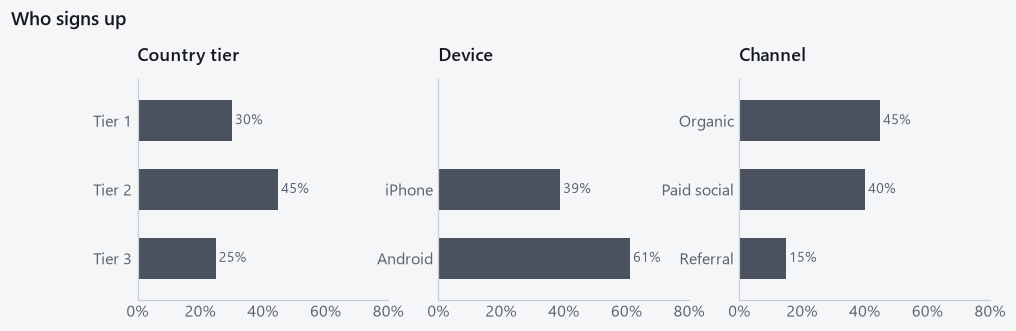

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.6), sharex=True)
for ax, (name, s) in zip(axes, comp.groupby(level=0, sort=False)):
    vals = s["share"].droplevel(0)
    ax.barh(vals.index[::-1], vals.values[::-1], color=CONTROL, height=0.6)
    ax.set_ylim(-0.6, 2.6)  # same bar thickness in every panel
    for y, v in enumerate(vals.values[::-1]):
        ax.text(v + 0.01, y, f"{v:.0%}", va="center", fontsize=9, color=MUTED)
    ax.set_title(name)
    ax.grid(False)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlim(0, 0.8)
fig.suptitle("Who signs up", x=0.01, ha="left", fontweight="semibold", y=1.12)
savefig(fig, "01_composition")

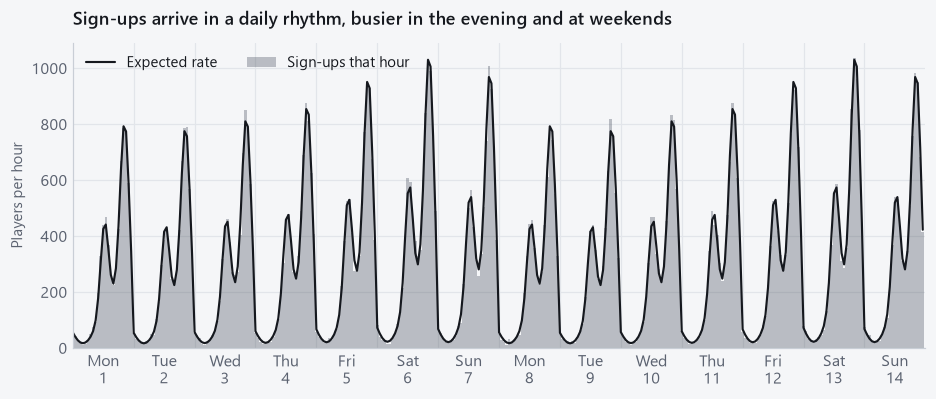

In [16]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(hours, counts, width=1.0, color=CONTROL, alpha=0.35, label="Sign-ups that hour")
ax.plot(hours, lam, color=INK, lw=1.4, label="Expected rate")
for d in range(1, CONFIG["days"]):
    ax.axvline(d * 24, color="#e2e5ea", lw=0.8, zorder=0)
ax.set_xticks(np.arange(12, CONFIG["days"] * 24, 24),
              [f"{WEEKDAYS[d % 7]}\n{d + 1}" for d in range(CONFIG["days"])])
ax.set_xlim(0, CONFIG["days"] * 24)
ax.set_ylabel("Players per hour")
ax.set_title("Sign-ups arrive in a daily rhythm, busier in the evening and at weekends")
ax.legend(loc="upper left", ncols=2)
savefig(fig, "01_arrivals_timeseries")

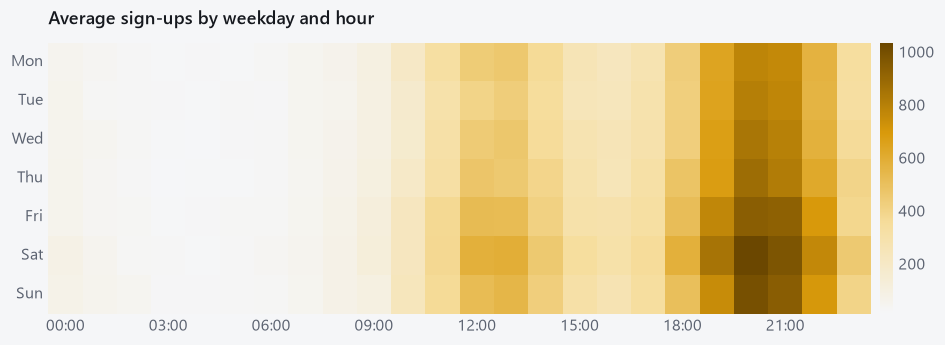

In [17]:
grid = np.zeros((7, 24))
np.add.at(grid, (df.weekday, df.hour_of_day), 1)
grid /= np.bincount((hours // 24) % 7, minlength=7)[:, None] / 24  # average per hour slot
grid = pd.DataFrame(grid, index=WEEKDAYS, columns=[f"{h:02d}:00" for h in range(24)])

fig, ax = plt.subplots(figsize=(10, 3.2))
sns.heatmap(grid, cmap=GOLD_CMAP, xticklabels=3, cbar_kws={"fraction": 0.025, "pad": 0.01}, ax=ax)
ax.tick_params(axis="both", rotation=0)
ax.set_xlabel("")
ax.set_title("Average sign-ups by weekday and hour")
savefig(fig, "01_arrivals_heatmap")

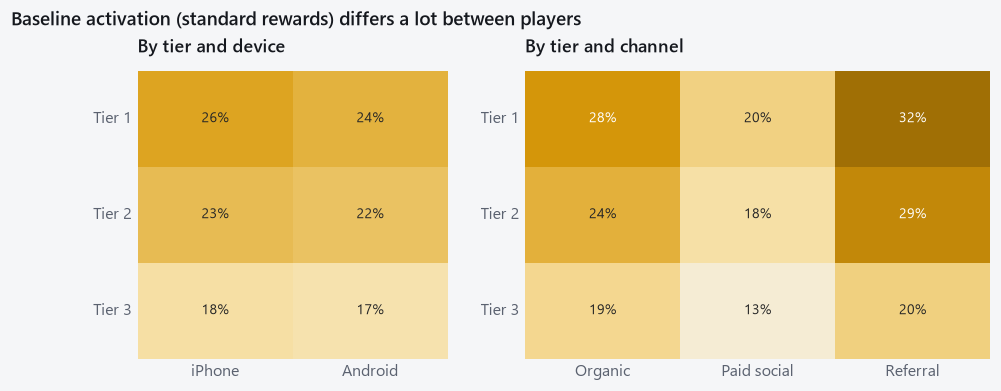

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [2, 3]})
for ax, col, levels in [(axes[0], "device", DEVICES), (axes[1], "channel", CHANNELS)]:
    M = (show[~show.treated].pivot_table(index="tier", columns=col, values="activated", aggfunc="mean")
         .reindex(index=TIERS, columns=levels))
    sns.heatmap(M, annot=True, fmt=".0%", cmap=GOLD_CMAP, vmin=0.10, vmax=0.36, cbar=False,
                annot_kws={"fontsize": 9}, ax=ax)
    ax.set(xlabel="", ylabel="")
    ax.tick_params(axis="y", rotation=0)
axes[0].set_title("By tier and device")
axes[1].set_title("By tier and channel")
fig.suptitle("Baseline activation (standard rewards) differs a lot between players",
             x=0.01, ha="left", fontweight="semibold", y=1.04)
savefig(fig, "01_baseline_heatmaps")

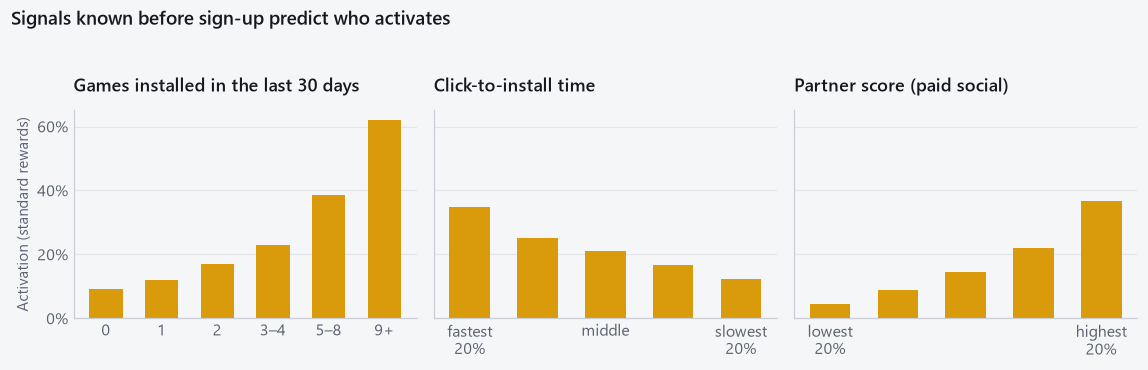

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.2), sharey=True)
c0 = show[~show.treated]
g = c0.groupby(pd.cut(c0.games_30d, [-1, 0, 1, 2, 4, 8, 1_000], labels=["0", "1", "2", "3–4", "5–8", "9+"]),
               observed=True).activated.mean()
axes[0].bar(g.index.astype(str), g.values, color=TREAT, width=0.6)
axes[0].set_title("Games installed in the last 30 days")
k = c0.groupby(pd.qcut(c0.click_to_install_s, 5, labels=False),
               observed=True).activated.mean()
axes[1].bar(range(5), k.values, color=TREAT, width=0.6)
axes[1].set_xticks(range(5), ["fastest\n20%", "", "middle", "", "slowest\n20%"])
axes[1].set_title("Click-to-install time")
sc = c0.dropna(subset=["partner_score"])
q = sc.groupby(pd.qcut(sc.partner_score, 5, labels=False), observed=True).activated.mean()
axes[2].bar(range(5), q.values, color=TREAT, width=0.6)
axes[2].set_xticks(range(5), ["lowest\n20%", "", "", "", "highest\n20%"])
axes[2].set_title("Partner score (paid social)")
axes[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].set_ylabel("Activation (standard rewards)")
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.suptitle("Signals known before sign-up predict who activates", x=0.01, ha="left", fontweight="semibold", y=1.04)
fig.tight_layout()
savefig(fig, "01_presignup_signals")

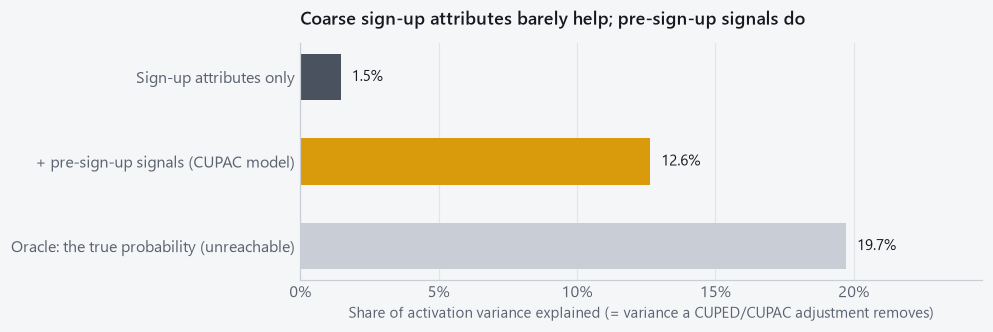

In [20]:
fig, ax = plt.subplots(figsize=(8, 2.8))
labels = ["Sign-up attributes only", "+ pre-sign-up signals (CUPAC model)", "Oracle: the true probability (unreachable)"]
colors = [CONTROL, TREAT, "#c9ced6"]
ax.barh(labels[::-1], r2.reindex(labels).values[::-1], color=colors[::-1], height=0.55)
for y, v in enumerate(r2.reindex(labels).values[::-1]):
    ax.text(v + 0.004, y, f"{v:.1%}", va="center", fontsize=10, color=INK)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlim(0, max(r2) * 1.25)
ax.grid(axis="y", visible=False)
ax.grid(axis="x")
ax.set_xlabel("Share of activation variance explained (= variance a CUPED/CUPAC adjustment removes)")
ax.set_title("Coarse sign-up attributes barely help; pre-sign-up signals do")
savefig(fig, "01_predictability")

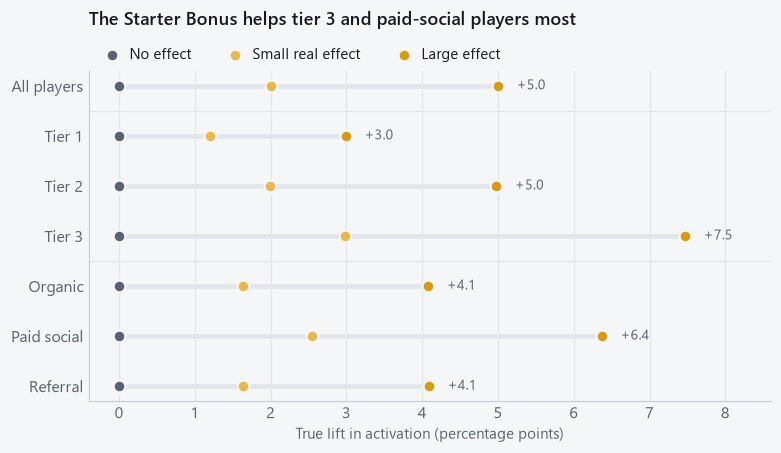

In [21]:
# True lift by segment, for each preset. Computed from the model, not estimated.
fig, ax = plt.subplots(figsize=(8, 3.9))
segments = [("All players", np.ones(len(df), bool))]
segments += [(t, (df.tier == i).values) for i, t in enumerate(TIERS)]
segments += [(c, (df.channel == i).values) for i, c in enumerate(CHANNELS)]
mult = raw_multiplier(df) / MULT_MEAN
preset_colors = {"No effect": MUTED, "Small real effect": "#e8b84a", "Large effect": TREAT}
ys = np.arange(len(segments))[::-1]
large = [CONFIG["presets"]["Large effect"] * mult[m].mean() * 100 for _, m in segments]
ax.hlines(ys, 0, large, color="#e2e5ea", lw=3, zorder=1)
for preset, lift in CONFIG["presets"].items():
    vals = [lift * mult[m].mean() * 100 for _, m in segments]
    ax.scatter(vals, ys, s=60, color=preset_colors[preset], label=preset, zorder=3,
               edgecolor="#f5f6f8", linewidth=1.5)
for y, v in zip(ys, large):
    ax.text(v + 0.25, y, f"{v:+.1f}", va="center", fontsize=9, color=MUTED)
ax.set_yticks(ys, [s for s, _ in segments])
ax.axhline(len(segments) - 1.5, color="#e2e5ea", lw=0.8)
ax.axhline(len(segments) - 4.5, color="#e2e5ea", lw=0.8)
ax.grid(axis="y", visible=False)
ax.grid(axis="x")
ax.set_xlim(-0.4, 8.6)
ax.set_xlabel("True lift in activation (percentage points)")
ax.set_title("The Starter Bonus helps tier 3 and paid-social players most", pad=30)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=3, borderaxespad=0.2, handletextpad=0.2)
savefig(fig, "01_true_lift_by_segment")

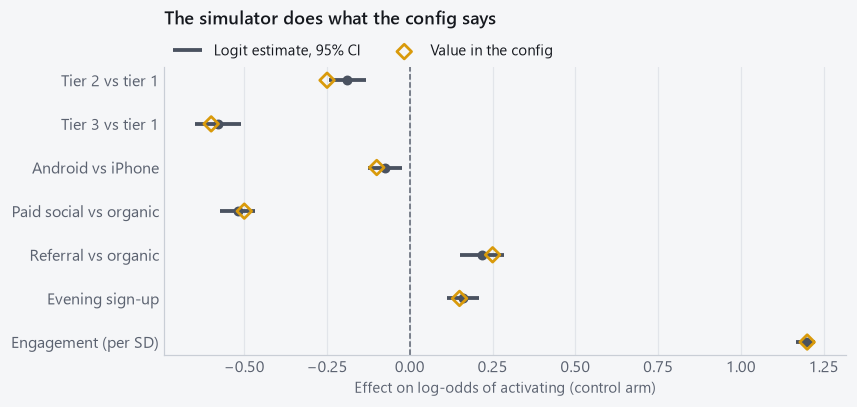

In [22]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ys = np.arange(len(recovery))[::-1]
ax.hlines(ys, recovery.ci_low, recovery.ci_high, color=CONTROL, lw=2.5, label="Logit estimate, 95% CI")
ax.scatter(recovery.estimate, ys, color=CONTROL, s=30, zorder=3)
ax.scatter(recovery.true, ys, marker="D", s=46, facecolor="none", edgecolor=TREAT, lw=1.8, zorder=4,
           label="Value in the config")
ax.axvline(0, color=MUTED, ls="--", lw=1)
ax.set_yticks(ys, recovery.index)
ax.grid(axis="y", visible=False)
ax.grid(axis="x")
ax.set_xlabel("Effect on log-odds of activating (control arm)")
ax.set_title("The simulator does what the config says", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=2, borderaxespad=0.2)
savefig(fig, "01_logit_recovery")

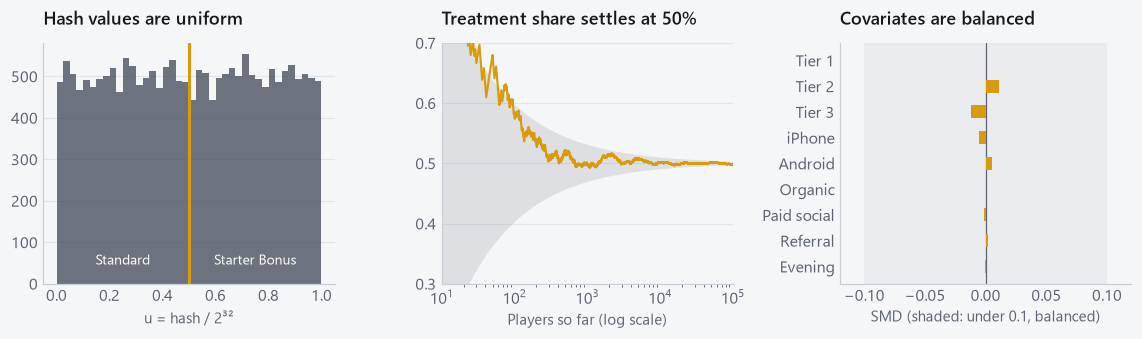

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.2))
probe = show.sample(20_000, random_state=0)
sns.histplot(probe.u, bins=40, color=CONTROL, alpha=0.8, linewidth=0, ax=axes[0])
axes[0].set_ylabel("")
axes[0].axvline(0.5, color=TREAT, lw=2)
axes[0].set_title("Hash values are uniform")
axes[0].set_xlabel("u = hash / 2³²")
axes[0].text(0.25, axes[0].get_ylim()[1] * 0.08, "Standard", ha="center", color="white", fontsize=9)
axes[0].text(0.75, axes[0].get_ylim()[1] * 0.08, "Starter Bonus", ha="center", color="white", fontsize=9)

n_seen = np.arange(1, len(df) + 1)
share = np.cumsum(df.treated.values) / n_seen
band = 1.96 * np.sqrt(0.25 / n_seen)
axes[1].fill_between(n_seen, 0.5 - band, 0.5 + band, color=MUTED, alpha=0.15, lw=0)
axes[1].plot(n_seen, share, color=TREAT, lw=1.4)
axes[1].set_xscale("log")
axes[1].set_xlim(10, len(df))
axes[1].set_ylim(0.3, 0.7)
axes[1].set_title("Treatment share settles at 50%")
axes[1].set_xlabel("Players so far (log scale)")

smd = table1.loc[features, "SMD"].astype(float)
axes[2].axvspan(-0.1, 0.1, color="#e2e5ea", alpha=0.6, lw=0, zorder=0)
axes[2].barh(smd.index[::-1], smd.values[::-1], color=TREAT, height=0.5, zorder=2)
axes[2].axvline(0, color=MUTED, lw=0.8, zorder=1)
axes[2].set_xlim(-0.12, 0.12)
axes[2].set_title("Covariates are balanced")
axes[2].set_xlabel("SMD (shaded: under 0.1, balanced)")
axes[2].grid(axis="y", visible=False)
fig.tight_layout()
savefig(fig, "01_assignment_checks")

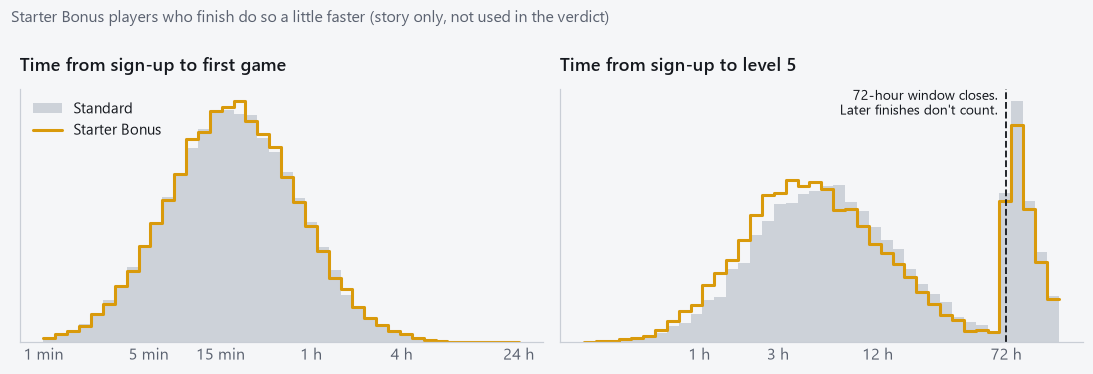

In [24]:
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator  # noqa: E402

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
journey = show.assign(minutes_to_start=show.hours_to_start * 60)
palette = {"Standard": CONTROL, "Starter Bonus": TREAT}
arms = {"Standard": dict(color="#c9ced6", fill=True, alpha=0.9, linewidth=0),
        "Starter Bonus": dict(color=TREAT, fill=False, linewidth=2)}
for arm, style in arms.items():
    d = journey[journey.arm == arm]
    sns.histplot(d, x="minutes_to_start", log_scale=True, element="step", stat="density", bins=40,
                 binrange=(0, np.log10(24 * 60)), label=arm, ax=axes[0], **style)
    sns.histplot(d, x="hours_to_milestone", log_scale=True, element="step", stat="density", bins=40,
                 binrange=(np.log10(0.2), np.log10(150)), ax=axes[1], **style)
for ax, ticks, labels in [(axes[0], [1, 5, 15, 60, 240, 1440], ["1 min", "5 min", "15 min", "1 h", "4 h", "24 h"]),
                          (axes[1], [1, 3, 12, 72], ["1 h", "3 h", "12 h", "72 h"])]:
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_major_formatter(FixedFormatter(labels))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_yticks([])
    ax.set(xlabel="", ylabel="")
    ax.grid(False)
axes[1].axvline(72, color=INK, lw=1.2, ls="--")
axes[1].text(64, axes[1].get_ylim()[1] * 0.9, "72-hour window closes.\nLater finishes don't count.",
             fontsize=9, color=INK, ha="right")
axes[0].set_title("Time from sign-up to first game")
axes[1].set_title("Time from sign-up to level 5")
axes[0].legend(loc="upper left")
fig.suptitle("Starter Bonus players who finish do so a little faster (story only, not used in the verdict)",
             x=0.01, ha="left", fontsize=10.5, color=MUTED, y=0.99)
fig.tight_layout()
savefig(fig, "01_journey_times")

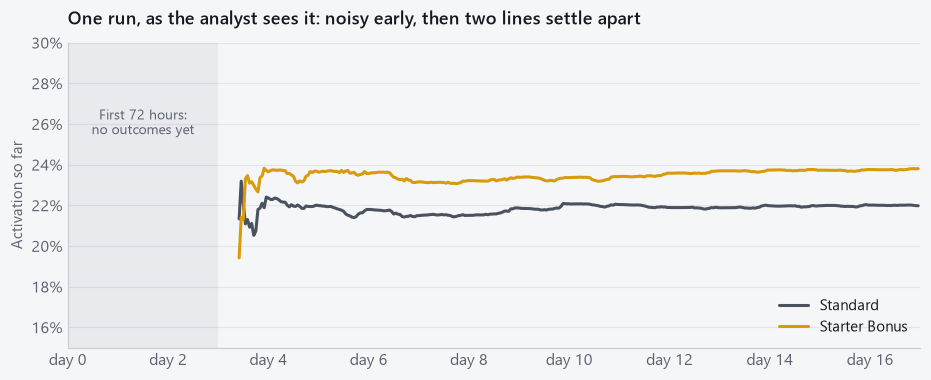

In [25]:
# What the analyst will see: cumulative activation by arm, as 72-hour windows close.
def cumulative_by_analysis_hour(d, horizon):
    out = {}
    for arm, mask in [("Standard", ~d.treated), ("Starter Bonus", d.treated)]:
        g = d[mask].groupby("analysed_at_hour").activated.agg(["sum", "size"]).reindex(
            range(horizon), fill_value=0).cumsum()
        out[arm] = (g["sum"] / g["size"]).where(g["size"] >= 300)  # hide the first, wildest hours
    return pd.DataFrame(out)


horizon = (CONFIG["days"] + 3) * 24
cum = cumulative_by_analysis_hour(df, horizon)

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.axvspan(0, 72, color=MUTED, alpha=0.08, lw=0)
ax.text(36, 0.255, "First 72 hours:\nno outcomes yet", ha="center", fontsize=9, color=MUTED)
ax.plot(cum.index, cum["Standard"], color=CONTROL, label="Standard")
ax.plot(cum.index, cum["Starter Bonus"], color=TREAT, label="Starter Bonus")
ax.set_xlim(0, horizon)
ax.set_ylim(0.15, 0.30)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xticks(np.arange(0, horizon + 1, 48), [f"day {h // 24}" for h in np.arange(0, horizon + 1, 48)])
ax.set_ylabel("Activation so far")
ax.set_title("One run, as the analyst sees it: noisy early, then two lines settle apart")
ax.legend(loc="lower right")
savefig(fig, "01_cumulative_preview")

## 6. Results

- The simulated world matches its spec: calibrated baseline of 22%, true average lift equal to the preset, and a daily and weekly sign-up rhythm.
- **Pre-sign-up signals matter.** Sign-up attributes alone explain under 2% of activation variance; adding games installed, click-to-install time and the partner score, a model trained on week 1 explains about 13% of week 2 (table above). That is the realistic room for CUPAC: roughly 13% fewer players for the same precision, in line with the 10–20% DoorDash reported.
- Hash assignment (`mmh3`) is uniform, gives a 50/50 split (χ² p well above 0.05), and leaves covariates balanced (every level's SMD far below 0.1, from `causalml`).
- A `statsmodels` logit fitted to the control arm recovers the coefficients in the config: the estimates sit close to the true values, and 6 of the 7 intervals contain them. With seven 95% intervals, at least one miss is expected about 30% of the time ($1 - 0.95^7$), so one narrow miss is consistent with a correct simulator.
- Segment effects are designed in (tier 3 and paid social benefit most). This is what the targeting article will try to recover.
- At 300 sign-ups an hour, two weeks is about 100,000 players, far more than the default preset needs. Notebook 04 tunes traffic, tick length and maximum sample so the default reaches a verdict in 60–90 seconds of viewing.
- Journey times are for the player story only. Nothing in the verdict uses them.

## Explore: sliders

Drag to see how the world changes. These three are the same three sliders the page will offer after the preset buttons. Widgets only work in a running notebook, not in a static export.

In [26]:
import ipywidgets as w  # noqa: E402


def explore(baseline=0.22, lift_points=2.0, per_hour=300):
    cfg = {**CONFIG, "baseline_rate": baseline, "arrivals": {**CONFIG["arrivals"], "per_hour": per_hour}}
    b0, mm = calibrate(cfg, n_ref=100_000)
    d, _ = simulate(lift_points / 100, cfg=cfg, intercept=b0, mult_mean=mm)
    c = cumulative_by_analysis_hour(d, horizon)
    fig, ax = plt.subplots(figsize=(9, 3.2))
    ax.plot(c.index, c["Standard"], color=CONTROL, label="Standard")
    ax.plot(c.index, c["Starter Bonus"], color=TREAT, label="Starter Bonus")
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_title(f"{len(d):,} players, true lift {(d.p1 - d.p0).mean() * 100:+.1f} points")
    ax.legend(loc="lower right")
    plt.show()


w.interact_manual(
    explore,
    baseline=w.FloatSlider(value=0.22, min=0.10, max=0.40, step=0.01, description="Baseline"),
    lift_points=w.FloatSlider(value=2.0, min=-2.0, max=8.0, step=0.5, description="True lift"),
    per_hour=w.IntSlider(value=300, min=50, max=1000, step=50, description="Traffic/h"),
);

interactive(children=(FloatSlider(value=0.22, description='Baseline', max=0.4, min=0.1, step=0.01), FloatSlide…

## 7. What gets promoted

| Function | Goes to | Guarded by |
|---|---|---|
| `CONFIG`, `INTERCEPT`, `MULT_MEAN` | `config/simulator.toml` (one documented file for Python and the browser) | `tests/test_simulator.py::test_calibration` |
| `assignment_u` | `ablab/assign.py` (wraps `mmh3`) | `tests/test_assign.py`; writes hash fixtures the TS port must match |
| `streams`, `draw_arrivals`, `draw_covariates`, `simulate` | `ablab/simulator.py` | `tests/test_simulator.py` (true lift = preset, baseline = 22%, 50/50 split) |
| Pre-sign-up signals and latent engagement | `config/simulator.toml` + `ablab/simulator.py` | `tests/test_simulator.py` (signal–engagement correlations within tolerance) |
| CUPAC model (gradient boosting vs logistic, chosen for browser portability) | settled in notebook 06; the page's final verdict uses it | `tests/test_cupac.py` |
| Balance and SRM | `ablab/checks.py` (from running counts, as the page needs) | `tests/test_checks.py` (agrees with `causalml.match.create_table_one` and `scipy.stats.chisquare`) |

## 8. Production parity

The code above now lives in `ablab/simulator.py` and `ablab/assign.py`, with every parameter in `config/simulator.toml`. This cell checks that production reproduces this notebook exactly: same seed, same players.

In [27]:
from ablab import simulator as prod  # noqa: E402
from ablab.config import load  # noqa: E402

toml = load()
assert np.allclose(prod.hour_shape(), HOUR_SHAPE) and np.allclose(prod.day_shape(), DAY_SHAPE)
assert toml["baseline_logit"] == CONFIG["baseline_logit"] and toml["lift_multiplier"] == CONFIG["lift_multiplier"]
assert abs(toml["calibration"]["intercept"] - INTERCEPT) < 1e-3
prod_df, _ = prod.simulate(0.02, seed=SEED, intercept=INTERCEPT, multiplier_mean=MULT_MEAN)
for col in ["player_id", "tier", "device", "channel", "games_30d", "treated", "activated", "p0", "p1"]:
    assert prod_df[col].equals(df[col]), col
print(f"ablab.simulator reproduces this notebook: {len(prod_df):,} identical players")

ablab.simulator reproduces this notebook: 100,723 identical players


## Further reading

Background for the simulated world: how online experiments are set up, and how to build a simulator whose true effect you control. Where to find them: **[local]** = `docs/papers/` in this project (kept out of the repo) · **[Vega: folder]** = `Vega/paper-library/pdfs/<folder>/` (Vega's library also has text versions in `paper-library/md/` and notes in `paper-library/papers/`) · **[online]** = not in either library yet. ★ = read first.

- ★ Kohavi, R., Tang, D., & Xu, Y. (2020). *Trustworthy Online Controlled Experiments: A Practical Guide to A/B Testing*. Cambridge University Press. The practitioner's reference: randomization units, metrics, guardrails. **[online]** https://doi.org/10.1017/9781108653985
- ★ Larsen, N., Stallrich, J., Sengupta, S., Deng, A., Kohavi, R., & Stevens, N. T. (2023). Statistical challenges in online controlled experiments: a review of A/B testing methodology. *The American Statistician*. The best single survey of the field. **[Vega: 05-power-and-decisions]** https://doi.org/10.1080/00031305.2023.2257237
- Evans, R. J., & Didelez, V. (2024). Parameterizing and simulating from causal models. *JRSS-B*. Building a simulator where the causal effect is a parameter you set. **[Vega: 13-dgp-simulation]**
- Orduz, J. C. The frugal parameterization for Bayesian causal inference in PyMC (blog). A worked example of the above. **[Vega: 13-dgp-simulation]**
- GrowthBook. *The Open Guide to A/B Testing* (v1.0). Practical pitfalls, in plain language. **[Vega: 08-personalization-and-platform-craft]**
- Fabijan, A., et al. (2019). Diagnosing sample ratio mismatch in online controlled experiments. *KDD 2019*. Why hash-based assignment is checked (more in notebook 05). **[online]** https://doi.org/10.1145/3292500.3330722